# importing libraries

In [15]:
import pandas as pd
import numpy as np
import matplotlib as mlt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.metrics import accuracy_score
%pip install scikit-learn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [16]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\Sukriti Singh\Documents\Intelligence System\JupyterNotebook
['.ipynb_checkpoints', 'Intelligence.ipynb']


# Load the datasets

In [17]:
import pandas as pd

customers = pd.read_csv("../datasets/customers_dataset.csv")
orders = pd.read_csv("../datasets/Order_datasets.csv")
items = pd.read_csv("../datasets/Order_items_datasets.csv")
products = pd.read_csv("../datasets/Product_datasets.csv")
reviews = pd.read_csv("../datasets/Order_review_datasets.csv")
# Check the datasets
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Products:", products.shape)
print("Reviews:", reviews.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Items: (112650, 7)
Products: (32951, 9)
Reviews: (99224, 7)


# Check missing values

In [18]:
print("Customers missing values:")
print(customers.isnull().sum())

print("\nOrders missing values:")
print(orders.isnull().sum())

print("\nProducts missing values:")
print(products.isnull().sum())

Customers missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Orders missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Products missing values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


# Check column names


In [19]:
print("CUSTOMERS")
print(customers.columns.tolist())

print("\nORDERS")
print(orders.columns.tolist())

print("\nORDER ITEMS")
print(items.columns.tolist())

print("\nPRODUCTS")
print(products.columns.tolist())

CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


#  Check duplicate records

In [20]:
print("Duplicate customers:", customers.duplicated().sum())
print("Duplicate orders:", orders.duplicated().sum())
print("Duplicate products:", products.duplicated().sum())

Duplicate customers: 0
Duplicate orders: 0
Duplicate products: 0


# Check missing values

In [21]:
missing = pd.DataFrame({
    "Customers": customers.isnull().sum(),
    "Orders": orders.isnull().sum(),
    "Order_Items": items.isnull().sum(),
    "Products": products.isnull().sum()
})

missing

,Customers,Orders,Order_Items,Products
customer_city,0.0,NaN,NaN,NaN
customer_id,0.0,0.0,NaN,NaN
customer_state,0.0,NaN,NaN,NaN
customer_unique_id,0.0,NaN,NaN,NaN
customer_zip_code_prefix,0.0,NaN,NaN,NaN
freight_value,NaN,NaN,0.0,NaN
order_approved_at,NaN,160.0,NaN,NaN
order_delivered_carrier_date,NaN,1783.0,NaN,NaN
order_delivered_customer_date,NaN,2965.0,NaN,NaN
order_estimated_delivery_date,NaN,0.0,NaN,NaN


In [22]:
orders.dtypes

order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

# Convert order date

In [23]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%d-%m-%Y %H:%M"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%d-%m-%Y %H:%M"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%d-%m-%Y %H:%M"
)

In [24]:
orders.dtypes

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                        object
order_delivered_carrier_date             object
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

# First visualization

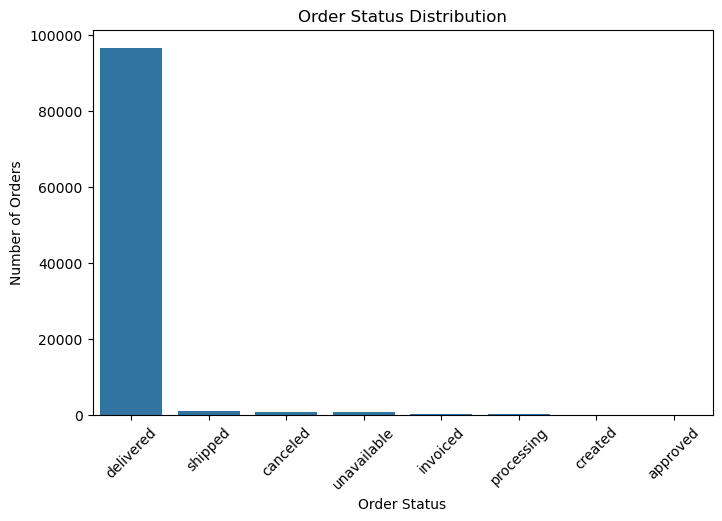

In [25]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=orders,
    x="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

# Our first business question

# calculate total orders:

In [26]:
total_orders = orders["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 99441


In [27]:
# delivered orders:

In [28]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
]["order_id"].nunique()

print("Delivered Orders:", delivered_orders)

Delivered Orders: 96478


In [29]:
# Create the sales dataset

In [30]:
sales = orders.merge(
    items,
    on="order_id",
    how="inner"
)

print("Sales dataset shape:", sales.shape)
sales.head()

Sales dataset shape: (112650, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,02-10-2017 11:07,04-10-2017 19:55,2017-10-10 21:25:00,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,06-10-2017 11:07,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,26-07-2018 03:24,26-07-2018 14:31,2018-08-07 15:27:00,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,30-07-2018 03:24,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,08-08-2018 08:55,08-08-2018 13:50,2018-08-17 18:06:00,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,13-08-2018 08:55,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,18-11-2017 19:45,22-11-2017 13:39,2017-12-02 00:28:00,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,23-11-2017 19:45,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,13-02-2018 22:20,14-02-2018 19:46,2018-02-16 18:17:00,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,19-02-2018 20:31,19.90,8.72


In [31]:
sales = sales.merge(
    products,
    on="product_id",
    how="left"
)

print("After merging products:", sales.shape)
sales.head()

After merging products: (112650, 22)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,02-10-2017 11:07,04-10-2017 19:55,2017-10-10 21:25:00,2017-10-18,1,87285b34884572647811a353c7ac498a,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,26-07-2018 03:24,26-07-2018 14:31,2018-08-07 15:27:00,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,08-08-2018 08:55,08-08-2018 13:50,2018-08-17 18:06:00,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,18-11-2017 19:45,22-11-2017 13:39,2017-12-02 00:28:00,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,13-02-2018 22:20,14-02-2018 19:46,2018-02-16 18:17:00,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


# Calculate Revenue

In [32]:
sales["revenue"] = sales["price"] * sales["order_item_id"].apply(
    lambda x: 1
)

In [33]:
sales["revenue"] = sales["price"]

In [34]:
sales[["order_id", "product_id", "price", "revenue"]].head()

,order_id,product_id,price,revenue
0,e481f51cbdc54678b7cc49136f2d6af7,87285b34884572647811a353c7ac498a,29.99,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,595fac2a385ac33a80bd5114aec74eb8,118.70,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,aa4383b373c6aca5d8797843e5594415,159.90,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,65266b2da20d04dbe00c5c2d3bb7859e,19.90,19.90


# Total revenue

In [35]:
total_revenue = sales["revenue"].sum()

print("Total Revenue: ₹", round(total_revenue, 2))

Total Revenue: ₹ 13591643.7


# Top 10 products

In [36]:
top_products = (
    sales.groupby("product_category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: revenue, dtype: float64

# Monthly sales

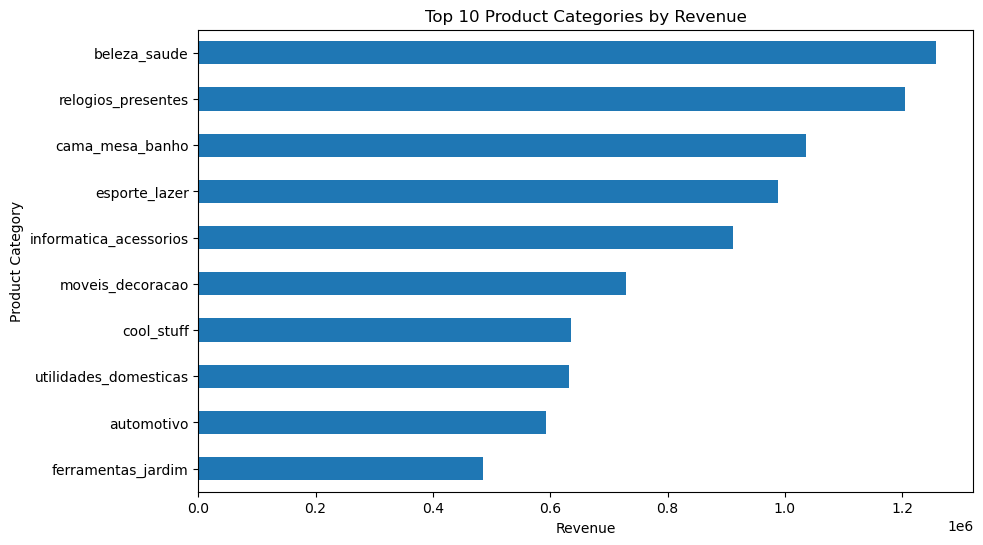

In [37]:
plt.figure(figsize=(10,6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.show()

 # Monthly sales

In [39]:
sales["month"] = sales["order_purchase_timestamp"].dt.to_period("M")

In [41]:
monthly_sales = (
    sales.groupby("month")["revenue"]
    .sum()
)

monthly_sales

month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: revenue, dtype: float64

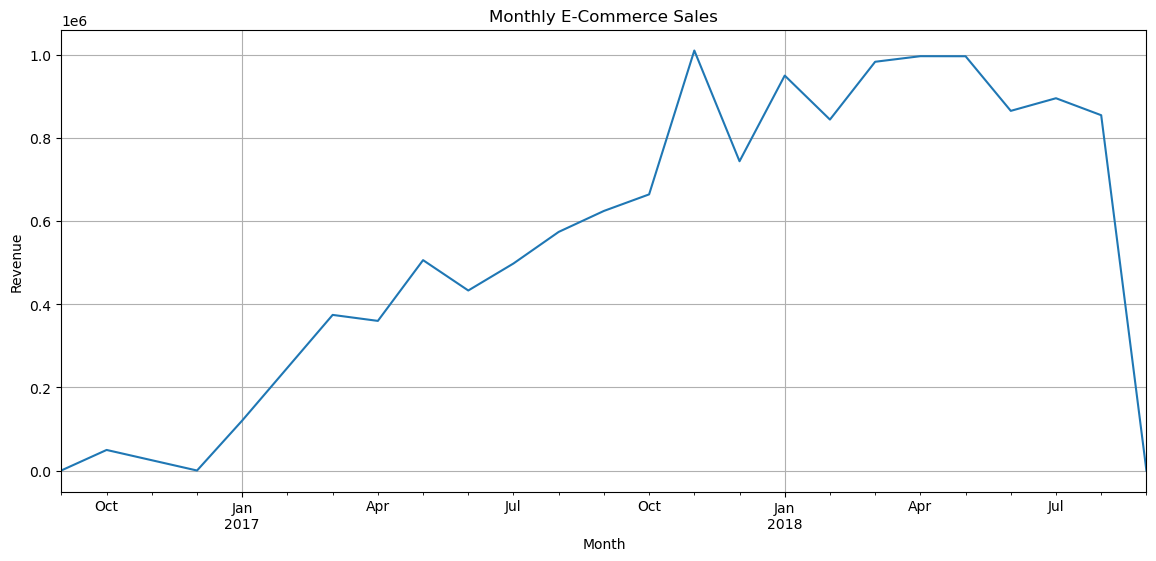

In [42]:
plt.figure(figsize=(14,6))

monthly_sales.plot()

plt.title("Monthly E-Commerce Sales")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.grid()
plt.show()

Customer Intelligence Dataset

In [44]:
customer_sales = sales.merge(
    customers,
    on="customer_id",
    how="left"
)

customer_sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,revenue,month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,02-10-2017 11:07,04-10-2017 19:55,2017-10-10 21:25:00,2017-10-18,1,87285b34884572647811a353c7ac498a,...,500.0,19.0,8.0,13.0,29.99,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,26-07-2018 03:24,26-07-2018 14:31,2018-08-07 15:27:00,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,400.0,19.0,13.0,19.0,118.70,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,08-08-2018 08:55,08-08-2018 13:50,2018-08-17 18:06:00,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,420.0,24.0,19.0,21.0,159.90,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,18-11-2017 19:45,22-11-2017 13:39,2017-12-02 00:28:00,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,450.0,30.0,10.0,20.0,45.00,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,13-02-2018 22:20,14-02-2018 19:46,2018-02-16 18:17:00,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,250.0,51.0,15.0,15.0,19.90,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
